# Aula 24 — Árvore de atingibilidade e cobertura em Redes de Petri

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O SCADA precisa distinguir estados de missão e transições permitidas. A rede de Petri modela PRONTA, DESLOCANDO, APLICANDO, PAUSADA, RETORNANDO e CONCLUIDA. O token representa a fase da missão, não litros, carga elétrica ou a posição contínua do drone.

Uma segunda rede representa o acúmulo de eventos aguardando confirmação de recebimento. Ela permite estudar cobertura com crescimento não limitado, conectando a teoria ao historiador e à telemetria do sistema.

## 2. Modelo e fundamentação

Uma rede P/T usa lugares, transições e matrizes Pre e Post. Uma transição $t$ está habilitada quando $M\geq Pre(:,t)$; seu disparo resulta em $M'=M-Pre(:,t)+Post(:,t)$. Na rede de missão há sempre um token: $\mathbf{1}^{T}M=1$. Logo os lugares são 1-limitados, e APLICANDO e PAUSADA não podem estar marcados simultaneamente.

A árvore de atingibilidade desdobra transições a partir de $M_0$. Uma marcação já descoberta é representada como folha repetida; o grafo correspondente funde repetições. A exploração completa da pequena rede encontra todas as marcações e identifica o estado terminal CONCLUIDA. Um limite de exploração excedido gera erro de análise incompleta.

Na rede de fila, produzir preserva um token de produtor e acrescenta um evento; confirmar consome um evento. Karp–Miller compara a marcação com seus ancestrais e substitui crescimento repetível por $\omega$. Cobertura pergunta se alguma marcação alcançável domina uma marcação-alvo; não exige igualdade. $\omega$ não representa uma quantidade física de memória nem uma marcação exata.

## 3. Procedimento e demonstração

1. Listar Pre e Post das transições da missão.
2. Construir o grafo e a árvore de atingibilidade com repetições identificadas.
3. Conferir o invariante de um token e a exclusão entre aplicação e pausa.
4. Construir a cobertura da fila e testar o alvo `(produtor=1, fila=100)`.
5. Comparar a rede limitada com a fila sem limite configurado.

Pergunta para a apresentação: uma folha sem transições é sempre um defeito? Não. CONCLUIDA é o término normal desta missão; um bloqueio inesperado em outra fase exigiria análise.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
def atingibilidade(transicoes, inicial, limite=1000):
    vistos = {inicial: 0}; marcas = [inicial]; arcos = []; arvore = []; fila = deque([inicial])
    while fila:
        m = fila.popleft()
        for nome, t in transicoes.items():
            if habilitada(m, t[0]):
                novo = disparar(m, t); repetido = novo in vistos
                if not repetido:
                    if len(marcas) >= limite: raise RuntimeError('Limite de estados: análise incompleta')
                    vistos[novo] = len(marcas); marcas.append(novo); fila.append(novo)
                arcos.append((vistos[m], vistos[novo], nome))
                arvore.append((vistos[m], vistos[novo], nome, repetido))
    return marcas, arcos, arvore


def arvore_atingibilidade(transicoes, inicial):
    """Desdobramento finito da rede limitada: repetições viram folhas referenciadas."""
    nodes=[dict(m=inicial,pai=None,via=None,repetido=False)]
    vistos={inicial}; fila=deque([0])
    while fila:
        i=fila.popleft(); m=nodes[i]['m']
        for nome,t in transicoes.items():
            if habilitada(m,t[0]):
                n=disparar(m,t); repetido=n in vistos
                nodes.append(dict(m=n,pai=i,via=nome,repetido=repetido))
                if not repetido:visto=n;vistos.add(visto);fila.append(len(nodes)-1)
    return nodes


In [3]:
def cobertura(transicoes, inicial, limite=1000):
    """Árvore Karp–Miller clássica para rede P/T, corte só por ancestral igual."""
    nodes = [dict(m=inicial, pai=None, via=None, repetido=False)]; pendentes = [0]
    while pendentes:
        i = pendentes.pop(); m = nodes[i]['m']; ancestrais = []; j = i
        while j is not None: ancestrais.append(nodes[j]['m']); j = nodes[j]['pai']
        if m in ancestrais[1:]: nodes[i]['repetido'] = True; continue
        for nome, t in transicoes.items():
            if not habilitada(m, t[0]): continue
            novo = disparar(m, t)
            # Repetir a aceleração até ponto fixo, usando apenas a cadeia de ancestrais.
            mudou = True
            while mudou:
                anterior = novo
                for a in ancestrais:
                    if all(x >= y for x, y in zip(novo, a)):
                        novo = tuple(math.inf if x > y else x for x, y in zip(novo, a))
                mudou = anterior != novo
            if len(nodes) >= limite: raise RuntimeError('Limite de nós: cobertura incompleta')
            nodes.append(dict(m=novo, pai=i, via=nome, repetido=False)); pendentes.append(len(nodes)-1)
    return nodes


### Rede limitada e árvore de atingibilidade

iniciar Pre= (1, 0, 0, 0, 0, 0) Post= (0, 1, 0, 0, 0, 0)
chegar Pre= (0, 1, 0, 0, 0, 0) Post= (0, 0, 1, 0, 0, 0)
pausar Pre= (0, 0, 1, 0, 0, 0) Post= (0, 0, 0, 1, 0, 0)
retomar Pre= (0, 0, 0, 1, 0, 0) Post= (0, 0, 1, 0, 0, 0)
finalizar_faixas Pre= (0, 0, 1, 0, 0, 0) Post= (0, 0, 0, 0, 1, 0)
abortar_pausa Pre= (0, 0, 0, 1, 0, 0) Post= (0, 0, 0, 0, 1, 0)
abortar_trajeto Pre= (0, 1, 0, 0, 0, 0) Post= (0, 0, 0, 0, 1, 0)
pousar Pre= (0, 0, 0, 0, 1, 0) Post= (0, 0, 0, 0, 0, 1)
Marcações: [(1, 0, 0, 0, 0, 0), (0, 1, 0, 0, 0, 0), (0, 0, 1, 0, 0, 0), (0, 0, 0, 0, 1, 0), (0, 0, 0, 1, 0, 0), (0, 0, 0, 0, 0, 1)]
Arcos: [(0, 1, 'iniciar'), (1, 2, 'chegar'), (1, 3, 'abortar_trajeto'), (2, 4, 'pausar'), (2, 3, 'finalizar_faixas'), (3, 5, 'pousar'), (4, 2, 'retomar'), (4, 3, 'abortar_pausa')]


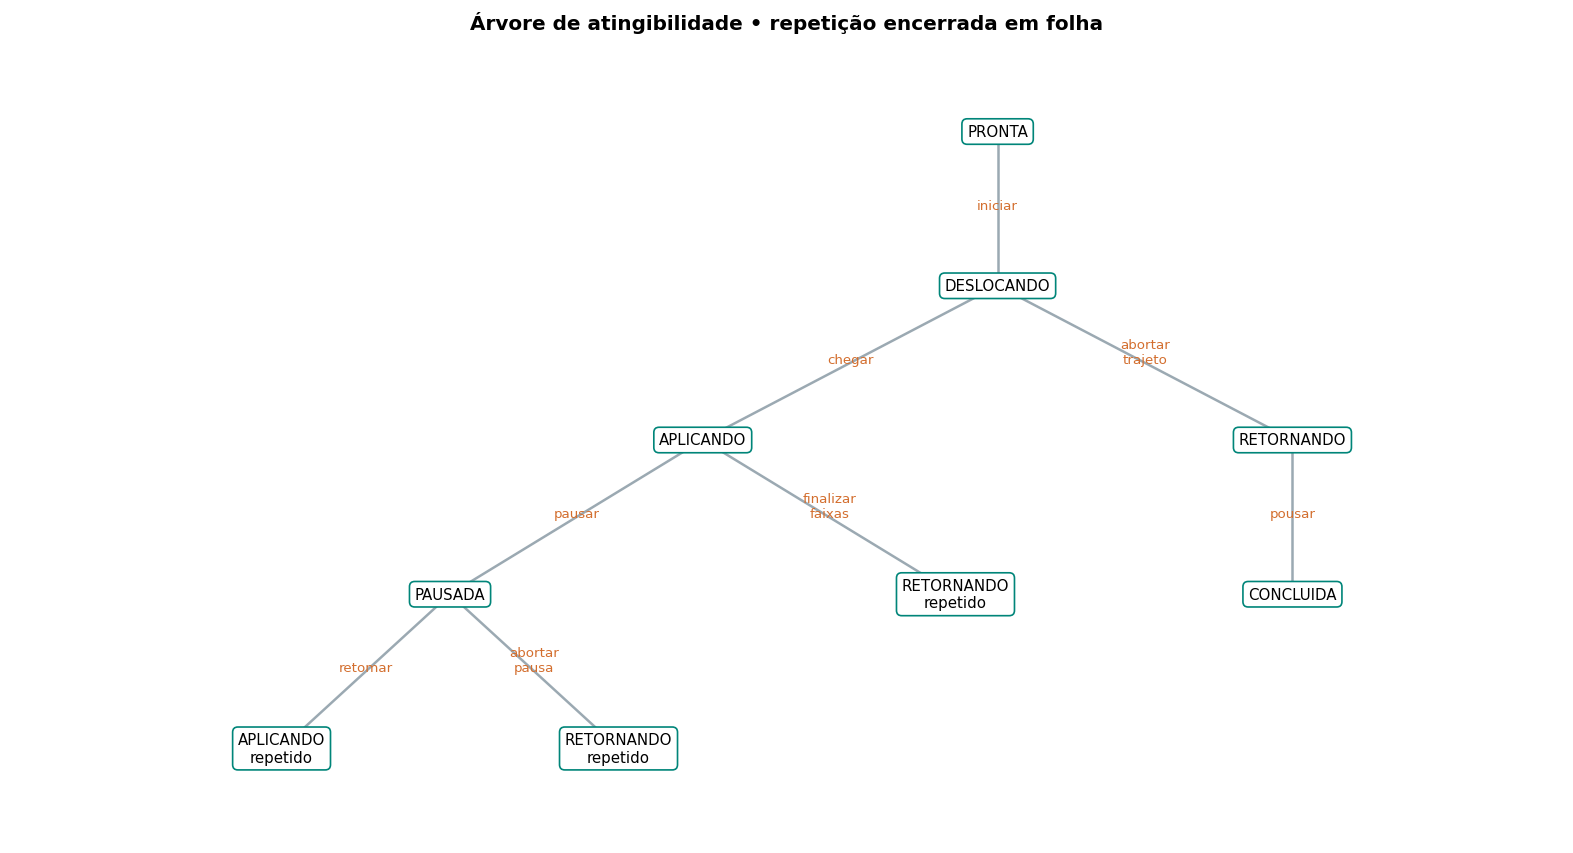

In [4]:
rede,m0=rede_missao()
for t,(pre,post) in rede.items():print(t,'Pre=',pre,'Post=',post)
marcas,arcos,_=atingibilidade(rede,m0)
print('Marcações:',marcas)
print('Arcos:',arcos)
assert all(sum(m)==1 for m in marcas)
vis.figura24_arvore();plt.show()

### Cobertura da fila de eventos

{'m': (1, 0), 'pai': None, 'via': None, 'repetido': False}
{'m': (1, inf), 'pai': 0, 'via': 'produzir', 'repetido': False}
{'m': (1, inf), 'pai': 1, 'via': 'produzir', 'repetido': True}
{'m': (1, inf), 'pai': 1, 'via': 'confirmar', 'repetido': True}


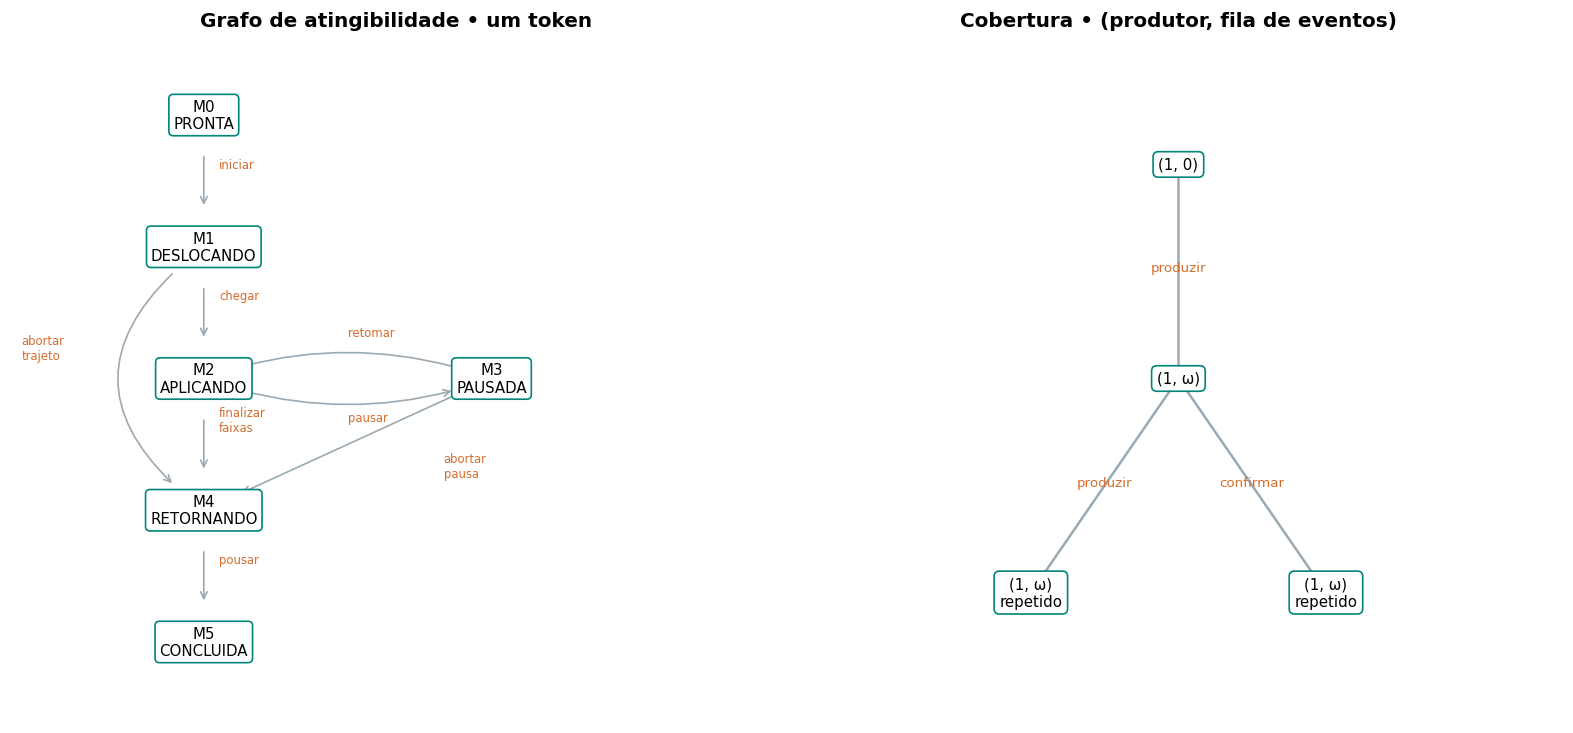

In [5]:
fila={'produzir':((1,0),(1,1)),'confirmar':((0,1),(0,0))}
for n in cobertura(fila,(1,0)):print(n)
vis.figura24();plt.show()

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [6]:
RESUMO = TESTES[24]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 24: APROVADAS')

{
  "marcacoes": 6,
  "arcos": 8,
  "nos_cobertura_fila": 4,
  "fila_ilimitada": true
}
Verificações da aula 24: APROVADAS


## 5. Interpretação, limites e continuidade

Os permissivos de vento, bateria, comunicação e aprovação são guardas externas verificadas pelo supervisor da Aula 25. A rede P/T não comprova essas condições contínuas. A transição retomar só é solicitada após a avaliação supervisória.

O resultado de cobertura mostra que uma política sem limite de fila permite acúmulo arbitrário. A solução operacional exigiria capacidade, descarte controlado ou contrapressão; nenhuma dessas políticas é presumida. O algoritmo de cobertura implementado aplica-se a redes P/T ordinárias, sem arcos inibidores ou resets. Na Aula 28, cada mudança de fase é conferida contra as marcações alcançáveis.

## 6. Referências

- [Berkeley — Petri Nets e coverability tree](https://chess.eecs.berkeley.edu/design/2010/lectures/mocPetri.pdf).
- [Esparza — Petri Nets, lecture notes](https://www.cse.iitb.ac.in/~akshayss/courses/cs735/Esparza-lecture-notes.pdf).